
# Apartado 6. Machine Learning

En este apartado se desarrolla un modelo de regresión para predecir el retraso de llegada de los vuelos, utilizando los datos preparados en la capa Gold.

Se compara un modelo de referencia basado en el promedio con un árbol de regresión. Ambos se evalúan mediante MAE y RMSE para identificar cuál obtiene mejores resultados.

Finalmente, se visualizan las predicciones y se guardan los modelos, las métricas y los resultados mediante MLflow.


In [0]:

# 1. Importar librerias
import pandas as pd
import numpy as np

# 2. Cargar datos de Gold
flights = spark.table("trabajo_final_aerolineas.gold.ml_flights")

print("Total de vuelos:", flights.count())
display(flights.limit(10))

# 3. Seleccionar variables para el modelo
columnas = [
    "airline_id",
    "origin_airport",
    "destination_airport",
    "departure_delay",
    "distance_km",
    "flight_month",
    "flight_quarter",
    "flight_weekday",
    "arrival_delay"
]

df = flights.select(*columnas).toPandas()

# 4. Separar variables de entrada y objetivo
X = df.drop(columns=["arrival_delay"])
y = df["arrival_delay"]

print("Registros para el modelo:", len(df))
print("Variables utilizadas:", list(X.columns))


Total de vuelos: 49244


flight_id,flight_date,airline_id,origin_airport,destination_airport,departure_delay,distance_km,flight_month,flight_quarter,flight_weekday,arrival_delay
FL-100022,2025-01-31,WN,SEA,DEN,-25,3971.85,1,1,6,-27
FL-100039,2025-02-10,DL,SFO,DFW,7,3807.7,2,1,2,-8
FL-100068,2025-01-17,NK,ORD,DFW,-1,732.25,1,1,6,1
FL-100072,2025-04-30,NK,MIA,ORD,20,2917.73,4,2,4,33
FL-100073,2025-01-22,B6,LAS,JFK,-10,651.78,1,1,4,-18
FL-100097,2025-05-14,B6,LAS,ATL,18,4200.38,5,2,4,27
FL-100115,2025-02-04,DL,LAS,SEA,-10,3056.14,2,1,3,-2
FL-100118,2025-05-27,UA,ATL,DFW,-36,2418.84,5,2,3,-29
FL-100132,2025-06-05,UA,JFK,LAX,0,1837.87,6,2,5,-8
FL-100147,2025-02-23,DL,LAX,LAS,12,1293.91,2,1,1,10


Registros para el modelo: 49244
Variables utilizadas: ['airline_id', 'origin_airport', 'destination_airport', 'departure_delay', 'distance_km', 'flight_month', 'flight_quarter', 'flight_weekday']


In [0]:

# 5. Importar herramientas de Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 6. Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7. Preparar variables
categoricas = ["airline_id", "origin_airport", "destination_airport"]
numericas = [
    "departure_delay", "distance_km",
    "flight_month", "flight_quarter", "flight_weekday"
]

preprocesamiento = ColumnTransformer([
    ("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore"))
    ]), categoricas),
    ("numericas", SimpleImputer(strategy="median"), numericas)
])

# 8. Crear modelos
modelo_referencia = Pipeline([
    ("preparar", preprocesamiento),
    ("modelo", DummyRegressor(strategy="mean"))
])

modelo_arbol = Pipeline([
    ("preparar", preprocesamiento),
    ("modelo", DecisionTreeRegressor(
        max_depth=8,
        min_samples_leaf=20,
        random_state=42
    ))
])

# 9. Entrenar
modelo_referencia.fit(X_train, y_train)
modelo_arbol.fit(X_train, y_train)

# 10. Obtener predicciones
pred_referencia = modelo_referencia.predict(X_test)
pred_arbol = modelo_arbol.predict(X_test)

print("Modelos entrenados correctamente")


Modelos entrenados correctamente


In [0]:

# 11. Evaluar los modelos con MAE y RMSE

resultados = pd.DataFrame([
    {
        "Modelo": "Referencia (promedio)",
        "MAE": mean_absolute_error(y_test, pred_referencia),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_referencia))
    },
    {
        "Modelo": "Arbol de regresion",
        "MAE": mean_absolute_error(y_test, pred_arbol),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_arbol))
    }
])

display(resultados.round(2))


Modelo,MAE,RMSE
Referencia (promedio),18.43,23.02
Arbol de regresion,8.15,10.25


In [0]:

# 11. Comparar los resultados de los modelos

resultados = pd.DataFrame([
    {
        "Modelo": "Referencia (promedio)",
        "MAE": mean_absolute_error(y_test, pred_referencia),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_referencia))
    },
    {
        "Modelo": "Arbol de regresion",
        "MAE": mean_absolute_error(y_test, pred_arbol),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_arbol))
    }
])

display(resultados.round(2))


Modelo,MAE,RMSE
Referencia (promedio),18.43,23.02
Arbol de regresion,8.15,10.25



## 6. Resultados y evaluación de los modelos

Se evaluaron dos modelos para predecir el retraso de llegada de los vuelos.

El modelo de referencia obtuvo un MAE de 18,43 minutos y un RMSE de 23,02 minutos. Por su parte, el árbol de regresión obtuvo un MAE de 8,15 minutos y un RMSE de 10,25 minutos.

El árbol de regresión presentó mejores resultados, ya que logró reducir el error de predicción utilizando la información de los vuelos. Por esta razón, se seleccionó como el modelo más adecuado de los dos evaluados.


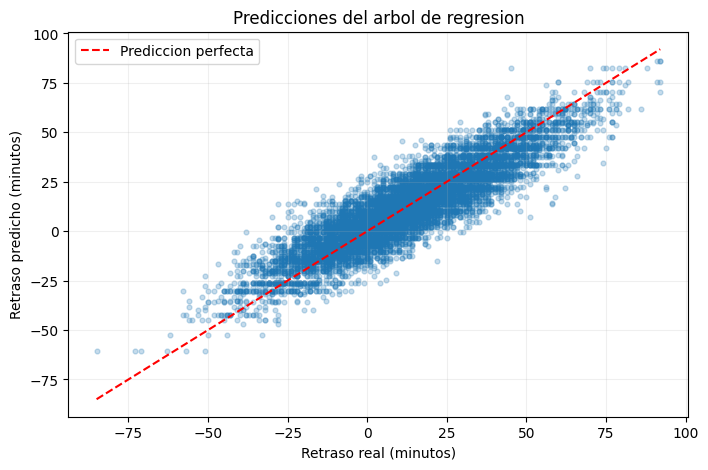

In [0]:

# 12. Comparar las predicciones con los valores reales

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, pred_arbol, alpha=0.25, s=12)

limite_min = min(y_test.min(), pred_arbol.min())
limite_max = max(y_test.max(), pred_arbol.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Prediccion perfecta"
)

plt.xlabel("Retraso real (minutos)")
plt.ylabel("Retraso predicho (minutos)")
plt.title("Predicciones del arbol de regresion")
plt.legend()
plt.grid(alpha=0.2)

plt.show()



## 7. Registro de resultados en MLflow

Se registran los modelos entrenados, sus parámetros y las métricas de evaluación en MLflow. También se guardan las predicciones para conservar los resultados y facilitar su consulta.


In [0]:

# 13. Guardar modelos, metricas y predicciones en MLflow

import mlflow
import mlflow.sklearn
import tempfile
import os

# Crear un experimento para el proyecto
mlflow.set_experiment("/Users/sotograjalesdaniela@gmail.com/Experimento_Retrasos_Vuelos")

# Preparar predicciones para guardar
predicciones = pd.DataFrame({
    "retraso_real": y_test.to_numpy(),
    "prediccion_referencia": pred_referencia,
    "prediccion_arbol": pred_arbol
})

# Registrar los dos modelos
modelos = [
    ("Referencia", modelo_referencia, pred_referencia),
    ("Arbol_Regresion", modelo_arbol, pred_arbol)
]

for nombre, modelo, pred in modelos:
    with mlflow.start_run(run_name=nombre):

        # Registrar metricas
        mlflow.log_metric("MAE", mean_absolute_error(y_test, pred))
        mlflow.log_metric("RMSE", np.sqrt(mean_squared_error(y_test, pred)))

        # Registrar parametros
        mlflow.log_param("modelo", nombre)
        mlflow.log_param("registros_entrenamiento", len(X_train))
        mlflow.log_param("registros_prueba", len(X_test))

        # Guardar modelo
        mlflow.sklearn.log_model(
            sk_model=modelo,
            name="modelo"
        )

# Guardar las predicciones como archivo del experimento
with tempfile.TemporaryDirectory() as carpeta:
    archivo = os.path.join(carpeta, "predicciones.csv")
    predicciones.to_csv(archivo, index=False)

    with mlflow.start_run(run_name="Resultados_Finales"):
        mlflow.log_artifact(archivo)
        mlflow.log_table(resultados, "metricas_modelos.json")

print("Modelos, metricas y predicciones registrados en MLflow")


2026/10/31 16:05:43 INFO mlflow.tracking.fluent: Experiment with name '/Users/sotograjalesdaniela@gmail.com/Experimento_Retrasos_Vuelos' does not exist. Creating a new experiment.
🔗 View Logged Model at: https://dbc-b9d20d85-0137.cloud.databricks.com/ml/experiments/1247485635637563/models/m-2a210f4fc5574b06bfb5d23b2432d489?o=7474656659502663
2026/10/31 16:05:49 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.
🔗 View Logged Model at: https://dbc-b9d20d85-0137.cloud.databricks.com/ml/experiments/1247485635637563/models/m-8aa81a5a548e4319a94f3c13eb679461?o=7474656659502663
2026/10/31 16:05:54 INFO mlf

Modelos, metricas y predicciones registrados en MLflow
